# IEEE 118-Bus System - Pre-Processing

This notebook loads the IEEE 118-bus system from pandapower, visualizes the network topology, and computes the DC power flow matrices (B, A, B', Φ) needed for the Optimal Transmission Switching (OTS) problem.

In [16]:
import numpy as np
import pandapower as pp
import pandapower.networks as pn
import pandapower.plotting as pplt
import matplotlib.pyplot as plt

## 1. Load the IEEE 118-Bus System

In [17]:
net = pn.case118()
print(f"Buses: {len(net.bus)}")
print(f"Lines: {len(net.line)}")
print(f"Transformers: {len(net.trafo)}")
print(f"Generators (gen): {len(net.gen)}")
print(f"Static generators (sgen): {len(net.sgen)}")
print(f"Loads: {len(net.load)}")
print(f"External grid (slack): {len(net.ext_grid)}")

Buses: 118
Lines: 173
Transformers: 13
Generators (gen): 53
Static generators (sgen): 0
Loads: 99
External grid (slack): 1


## 2. Explore the Data

In [18]:
print("--- Bus Data (first 10) ---")
net.bus.head(10)

--- Bus Data (first 10) ---


,name,vn_kv,type,zone,in_service,max_vm_pu,min_vm_pu,geo
0,1,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-2.2753708781, 2.8543413351],..."
1,2,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-2.9368186836, 2.2121792656],..."
2,3,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-1.8344312496, 1.7094451782],..."
3,4,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-0.8886268958, 1.5532705585],..."
4,5,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-0.9632829393, 0.694729907], ..."
5,6,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-0.4109732139, 1.7675722497],..."
6,7,138.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-1.4836496595, 2.2620419749],..."
7,8,345.0,b,1.0,True,1.06,0.94,"{""coordinates"": [-0.6792997874, -0.5813210368]..."
8,9,345.0,b,1.0,True,1.06,0.94,"{""coordinates"": [0.492210326, 0.0395449742], ""..."
9,10,345.0,b,1.0,True,1.06,0.94,"{""coordinates"": [1.5086493002, 0.7537990673], ..."


In [19]:
print("--- Line Data (first 10) ---")
net.line.head(10)

--- Line Data (first 10) ---


,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,max_loading_percent,geo
0,None,None,0,1,1.0,5.770332,19.024956,353.789081,0.0,41.418606,1.0,1,ol,True,100.0,None
1,None,None,0,2,1.0,2.456676,8.074656,150.708577,0.0,41.418606,1.0,1,ol,True,100.0,None
2,None,None,3,4,1.0,0.335174,1.519711,29.250278,0.0,41.418606,1.0,1,ol,True,100.0,None
3,None,None,2,4,1.0,4.589604,20.567520,395.575193,0.0,41.418606,1.0,1,ol,True,100.0,None
4,None,None,4,5,1.0,2.266236,10.283760,198.623319,0.0,41.418606,1.0,1,ol,True,100.0,None
5,None,None,5,6,1.0,0.874120,3.961152,76.607872,0.0,41.418606,1.0,1,ol,True,100.0,None
6,None,None,7,8,1.0,2.904210,36.302625,2589.624643,0.0,16.567443,1.0,1,ol,True,100.0,None
7,None,None,8,9,1.0,3.070845,38.326050,2741.168942,0.0,16.567443,1.0,1,ol,True,100.0,None
8,None,None,3,10,1.0,3.980196,13.102272,243.473745,0.0,41.418606,1.0,1,ol,True,100.0,None
9,None,None,4,10,1.0,3.865932,12.988008,242.080875,0.0,41.418606,1.0,1,ol,True,100.0,None


In [20]:
print("--- Transformer Data ---")
net.trafo

--- Transformer Data ---


,name,std_type,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,...,tap_min,tap_max,tap_step_percent,tap_step_degree,tap_pos,parallel,df,in_service,max_loading_percent,tap_changer_type
0,None,None,7,4,9900.0,345.0,138.0,264.330000,0.000,0.0,...,NaN,NaN,1.5,NaN,-1.0,1,1.0,True,100.0,Ratio
1,None,None,25,24,9900.0,345.0,138.0,378.180000,0.000,0.0,...,NaN,NaN,4.0,NaN,-1.0,1,1.0,True,100.0,Ratio
2,None,None,29,16,9900.0,345.0,138.0,384.120000,0.000,0.0,...,NaN,NaN,4.0,NaN,-1.0,1,1.0,True,100.0,Ratio
3,None,None,37,36,9900.0,345.0,138.0,371.250000,0.000,0.0,...,NaN,NaN,6.5,NaN,-1.0,1,1.0,True,100.0,Ratio
4,None,None,62,58,9900.0,345.0,138.0,382.140000,0.000,0.0,...,NaN,NaN,4.0,NaN,-1.0,1,1.0,True,100.0,Ratio
5,None,None,63,60,9900.0,345.0,138.0,265.320000,0.000,0.0,...,NaN,NaN,1.5,NaN,-1.0,1,1.0,True,100.0,Ratio
6,None,None,64,65,9900.0,345.0,138.0,366.300000,0.000,0.0,...,NaN,NaN,6.5,NaN,-1.0,1,1.0,True,100.0,Ratio
7,None,None,64,67,9900.0,345.0,161.0,158.988082,13.662,0.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,True,100.0,None
8,None,None,67,68,9900.0,161.0,138.0,366.300000,0.000,0.0,...,NaN,NaN,6.5,NaN,-1.0,1,1.0,True,100.0,Ratio
9,None,None,80,67,9900.0,345.0,161.0,200.729061,17.325,0.0,...,NaN,NaN,NaN,NaN,NaN,1,1.0,True,100.0,None


In [21]:
print("--- Generator Data (first 10) ---")
net.gen.head(10)

--- Generator Data (first 10) ---


,name,bus,p_mw,vm_pu,sn_mva,min_q_mvar,max_q_mvar,scaling,slack,in_service,slack_weight,type,controllable,max_p_mw,min_p_mw,id_q_capability_characteristic,reactive_capability_curve,curve_style
0,None,0,0.0,0.955,NaN,-5.0,15.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
1,None,3,0.0,0.998,NaN,-300.0,300.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
2,None,5,0.0,0.990,NaN,-13.0,50.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
3,None,7,0.0,1.015,NaN,-300.0,300.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
4,None,9,450.0,1.050,NaN,-147.0,200.0,1.0,False,True,0.0,None,True,550.0,0.0,<NA>,False,None
5,None,11,85.0,0.990,NaN,-35.0,120.0,1.0,False,True,0.0,None,True,185.0,0.0,<NA>,False,None
6,None,14,0.0,0.970,NaN,-10.0,30.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
7,None,17,0.0,0.973,NaN,-16.0,50.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
8,None,18,0.0,0.962,NaN,-8.0,24.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None
9,None,23,0.0,0.992,NaN,-300.0,300.0,1.0,False,True,0.0,None,True,100.0,0.0,<NA>,False,None


In [22]:
print("--- Load Data (first 10) ---")
net.load.head(10)

--- Load Data (first 10) ---


,name,bus,p_mw,q_mvar,const_z_p_percent,const_z_q_percent,const_i_p_percent,const_i_q_percent,sn_mva,scaling,in_service,type,controllable
0,None,0,51.0,27.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
1,None,1,20.0,9.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
2,None,2,39.0,10.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
3,None,3,39.0,12.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
4,None,5,52.0,22.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
5,None,6,19.0,2.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
6,None,7,28.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
7,None,10,70.0,23.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
8,None,11,47.0,10.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
9,None,12,34.0,16.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False


## 3. Network Topology Plot

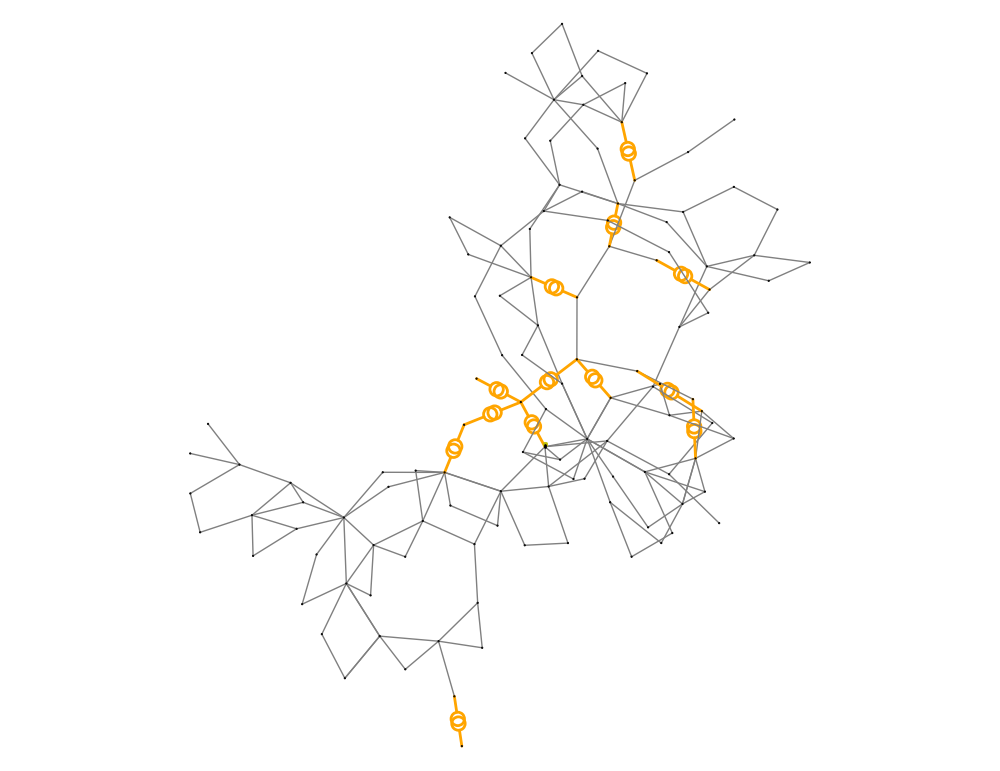

<Axes: >

In [23]:
from pandapower.plotting import simple_plot

simple_plot(net, show_plot=True, bus_size=0.06, bus_color='black',
            line_color='grey', trafo_color='orange',
            ext_grid_size=0.1, plot_line_switches=False)

## 4. Build Unified Branch Data

For the DC power flow, we combine transmission lines and transformers into a single branch list with reactance in per-unit.

In [24]:
base_mva = net.sn_mva  # system base MVA
print(f"System base: {base_mva} MVA")

branches_from = []
branches_to = []
branches_x = []
branches_rate = []

# Transmission lines
for idx, line in net.line.iterrows():
    from_bus = line["from_bus"]
    to_bus = line["to_bus"]
    vn_kv = net.bus.at[from_bus, "vn_kv"]
    z_base = (vn_kv ** 2) / base_mva
    x_pu = (line["x_ohm_per_km"] * line["length_km"]) / z_base
    rate_mva = line["max_i_ka"] * vn_kv * np.sqrt(3)
    branches_from.append(from_bus)
    branches_to.append(to_bus)
    branches_x.append(x_pu)
    branches_rate.append(rate_mva)

# Transformers
for idx, trafo in net.trafo.iterrows():
    from_bus = trafo["hv_bus"]
    to_bus = trafo["lv_bus"]
    x_pu = (trafo["vk_percent"] / 100.0) * (base_mva / trafo["sn_mva"])
    rate_mva = trafo["sn_mva"]
    branches_from.append(from_bus)
    branches_to.append(to_bus)
    branches_x.append(x_pu)
    branches_rate.append(rate_mva)

branches_from = np.array(branches_from, dtype=int)
branches_to = np.array(branches_to, dtype=int)
branches_x = np.array(branches_x)
branches_rate = np.array(branches_rate)

num_buses = len(net.bus)
num_branches = len(branches_x)

print(f"\nTotal branches: {num_branches}")
print(f"  Lines: {len(net.line)}")
print(f"  Transformers: {len(net.trafo)}")

System base: 100 MVA

Total branches: 186
  Lines: 173
  Transformers: 13


## 5. DC Power Flow Matrices

We compute:
- **B** — Branch Susceptance Matrix (diagonal, $b_l = 1/x_l$)
- **A** — Incidence Matrix (branches × non-slack buses)
- **B'** — Bus Susceptance Matrix ($A^T B A$)
- **Φ (Phi)** — Sensitivity / PTDF Matrix ($B \cdot A \cdot (B')^{-1}$)

In [25]:
# Slack bus
slack_bus = net.ext_grid.at[0, "bus"]
print(f"Slack bus: {slack_bus}")

# Non-slack buses and mapping
all_buses = net.bus.index.values
non_slack_buses = [b for b in all_buses if b != slack_bus]
bus_to_col = {bus: idx for idx, bus in enumerate(non_slack_buses)}

# Handle zero reactances
zero_x_mask = branches_x == 0
if zero_x_mask.any():
    print(f"WARNING: {zero_x_mask.sum()} branches with zero reactance (replaced with 1e-6)")
    branches_x[zero_x_mask] = 1e-6

print(f"\nMatrix dimensions:")
print(f"  B: {num_branches} x {num_branches}")
print(f"  A: {num_branches} x {num_buses - 1}")
print(f"  B': {num_buses - 1} x {num_buses - 1}")
print(f"  Phi: {num_branches} x {num_buses - 1}")

Slack bus: 68

Matrix dimensions:
  B: 186 x 186
  A: 186 x 117
  B': 117 x 117
  Phi: 186 x 117


In [26]:
# B: Branch Susceptance Matrix
B = np.diag(1.0 / branches_x)

# A: Incidence Matrix
A = np.zeros((num_branches, num_buses - 1))
for i in range(num_branches):
    f = branches_from[i]
    t = branches_to[i]
    if f in bus_to_col:
        A[i, bus_to_col[f]] = 1
    if t in bus_to_col:
        A[i, bus_to_col[t]] = -1

# B': Bus Susceptance Matrix
B_prime = A.T @ B @ A

# Phi: Sensitivity Matrix (PTDF)
B_prime_inv = np.linalg.inv(B_prime)
Phi = B @ A @ B_prime_inv

print("Pre-processing completed!")
print(f"B shape: {B.shape}")
print(f"A shape: {A.shape}")
print(f"B' shape: {B_prime.shape}")
print(f"Phi shape: {Phi.shape}")

Pre-processing completed!
B shape: (186, 186)
A shape: (186, 117)
B' shape: (117, 117)
Phi shape: (186, 117)


## 6. Visualize Matrices

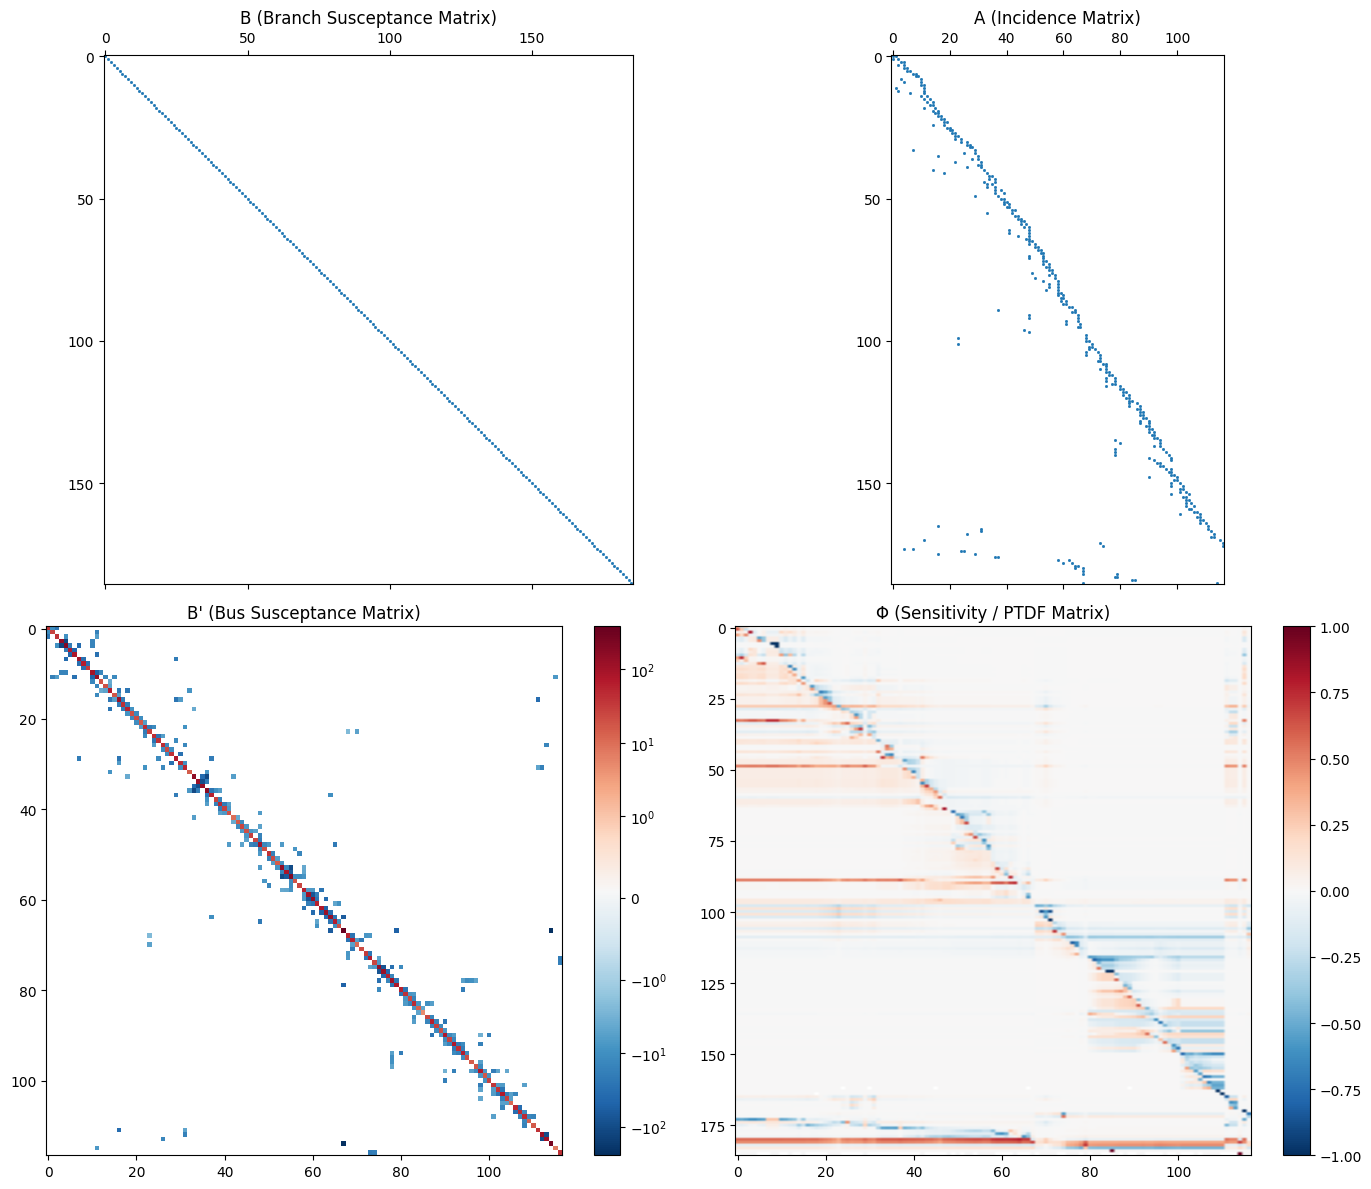

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# B matrix (show sparsity pattern since it's diagonal)
axes[0, 0].spy(B, markersize=1)
axes[0, 0].set_title("B (Branch Susceptance Matrix)")

# A matrix
axes[0, 1].spy(A, markersize=1)
axes[0, 1].set_title("A (Incidence Matrix)")

# B' matrix - mask zeros so they appear white
from matplotlib.colors import SymLogNorm
B_prime_masked = np.ma.masked_where(B_prime == 0, B_prime)
norm = SymLogNorm(linthresh=1, linscale=1, vmin=B_prime.min(), vmax=B_prime.max())
cmap_bp = plt.cm.RdBu_r.copy()
cmap_bp.set_bad(color='white')
im = axes[1, 0].imshow(B_prime_masked, aspect='auto', cmap=cmap_bp, norm=norm)
axes[1, 0].set_title("B' (Bus Susceptance Matrix)")
plt.colorbar(im, ax=axes[1, 0])

# Phi matrix - mask zeros so they appear white
Phi_masked = np.ma.masked_where(Phi == 0, Phi)
cmap_phi = plt.cm.RdBu_r.copy()
cmap_phi.set_bad(color='white')
im2 = axes[1, 1].imshow(Phi_masked, aspect='auto', cmap=cmap_phi)
axes[1, 1].set_title("Φ (Sensitivity / PTDF Matrix)")
plt.colorbar(im2, ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [28]:
# Numerical view of first 10x10
np.set_printoptions(precision=3, suppress=True, linewidth=120)

print("B (Branch Susceptance Matrix, first 10x10):")
print(B[:10, :10])
print()
print("A (Incidence Matrix, first 10x10):")
print(A[:10, :10])

B (Branch Susceptance Matrix, first 10x10):
[[ 10.01    0.      0.      0.      0.      0.      0.      0.      0.      0.   ]
 [  0.     23.585   0.      0.      0.      0.      0.      0.      0.      0.   ]
 [  0.      0.    125.313   0.      0.      0.      0.      0.      0.      0.   ]
 [  0.      0.      0.      9.259   0.      0.      0.      0.      0.      0.   ]
 [  0.      0.      0.      0.     18.519   0.      0.      0.      0.      0.   ]
 [  0.      0.      0.      0.      0.     48.077   0.      0.      0.      0.   ]
 [  0.      0.      0.      0.      0.      0.     32.787   0.      0.      0.   ]
 [  0.      0.      0.      0.      0.      0.      0.     31.056   0.      0.   ]
 [  0.      0.      0.      0.      0.      0.      0.      0.     14.535   0.   ]
 [  0.      0.      0.      0.      0.      0.      0.      0.      0.     14.663]]

A (Incidence Matrix, first 10x10):
[[ 1. -1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 1.  0. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 

In [29]:
print("B' (Bus Susceptance Matrix, first 10x10):")
print(B_prime[:10, :10])
print()
print("Phi (Sensitivity / PTDF Matrix, first 10x10):")
print(Phi[:10, :10])

B' (Bus Susceptance Matrix, first 10x10):
[[  33.595  -10.01   -23.585    0.       0.       0.       0.       0.       0.       0.   ]
 [ -10.01    26.244    0.       0.       0.       0.       0.       0.       0.       0.   ]
 [ -23.585    0.      39.094    0.      -9.259    0.       0.       0.       0.       0.   ]
 [   0.       0.       0.     139.848 -125.313    0.       0.       0.       0.       0.   ]
 [   0.       0.      -9.259 -125.313  205.207  -18.519    0.     -37.453    0.       0.   ]
 [   0.       0.       0.       0.     -18.519   66.595  -48.077    0.       0.       0.   ]
 [   0.       0.       0.       0.       0.     -48.077   77.489    0.       0.       0.   ]
 [   0.       0.       0.       0.     -37.453    0.       0.      90.081  -32.787    0.   ]
 [   0.       0.       0.       0.       0.       0.       0.     -32.787   63.843  -31.056]
 [   0.       0.       0.       0.       0.       0.       0.       0.     -31.056   31.056]]

Phi (Sensitivity / PTDF Ma